In [190]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [191]:
data = pd.read_csv('mnist_train.csv')

In [192]:
data = np.array(data)
m,n = data.shape
np.random.shuffle(data)

In [193]:
data_Dev = data[0:1000].T
Y_dev = data_Dev[0]
X_dev = data_Dev[1:n]/255
data_train = data[1000:m].T
Y_train = data_train[0]
X_train = data_train[1:n]/255

In [194]:
def init_params():
    W1 = np.random.randn(10,784) * np.sqrt(2/784)
    b1 = np.zeros((10,1))

    W2 = np.random.randn(10,10) * np.sqrt(2/10)
    b2 = np.zeros((10,1))

    return W1,b1,W2,b2

In [195]:
def ReLU(Z):
    return np.maximum(0,Z)

In [196]:
def softmax(Z):
    exp = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return exp / np.sum(exp, axis=0, keepdims=True)

In [197]:
def forward_prop(W1,b1,W2,b2,X):
    Z1 = W1.dot(X)+b1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1)+b2
    A2 = softmax(Z2)
    return Z1, A1,Z2,A2

In [198]:
def one_hot(Y):
    one_hot_Y = np.zeros((Y.size, Y.max()+1))
    one_hot_Y[np.arange(Y.size),Y] = 1
    return one_hot_Y.T

In [199]:
def deriv_ReLU(Z):
    return Z>0

In [200]:
def back_prop(Z1,A1,Z2,A2,W2,X,Y):
    m = Y.size

    one_hot_Y = one_hot(Y)

    dZ2 = A2 - one_hot_Y
    dW2 = (1/m) * dZ2.dot(A1.T)
    db2 = (1/m) * np.sum(dZ2, axis=1, keepdims=True)

    dZ1 = W2.T.dot(dZ2) * deriv_ReLU(Z1)
    dW1 = (1/m) * dZ1.dot(X.T)
    db1 = (1/m) * np.sum(dZ1, axis=1, keepdims=True)

    return dW1,db1,dW2,db2

In [201]:

def update_params(W1,b1,W2,b2,dW1,db1,dW2,db2,alpha):
    W1 = W1 - alpha*dW1
    b1 = b1 - alpha*db1
    W2 = W2 - alpha*dW2
    b2 = b2 - alpha*db2
    return W1,b1,W2,b2

In [202]:
def get_predictions(A2):
    return np.argmax(A2,0)
def get_accuracy(predictions,Y):
    return np.sum(predictions == Y)/Y.size    


In [203]:
def gradient_descent(X,Y,iterations,alpha):
    W1,b1,W2,b2 = init_params()

    for i in range(iterations):
        Z1,A1,Z2,A2 = forward_prop(W1,b1,W2,b2,X)

        dW1,db1,dW2,db2 = back_prop(
            Z1,A1,Z2,A2,W2,X,Y
        )

        W1,b1,W2,b2 = update_params(
            W1,b1,W2,b2,
            dW1,db1,dW2,db2,alpha
        )

        if i % 10 == 0:
            print("Iteration:", i)
            print("Accuracy", get_accuracy(get_predictions(A2),Y))

    return W1,b1,W2,b2

In [204]:
W1,b1,W2,b2 = gradient_descent(
    X_train,Y_train,500,0.1
)

Iteration: 0
Accuracy 0.11803389830508475
Iteration: 10
Accuracy 0.38601694915254237
Iteration: 20
Accuracy 0.5020169491525424
Iteration: 30
Accuracy 0.6277966101694915
Iteration: 40
Accuracy 0.7465593220338983
Iteration: 50
Accuracy 0.791271186440678
Iteration: 60
Accuracy 0.8132203389830508
Iteration: 70
Accuracy 0.8279322033898305
Iteration: 80
Accuracy 0.8389661016949153
Iteration: 90
Accuracy 0.8471016949152542
Iteration: 100
Accuracy 0.8534237288135593
Iteration: 110
Accuracy 0.8591016949152542
Iteration: 120
Accuracy 0.8635593220338983
Iteration: 130
Accuracy 0.8677966101694915
Iteration: 140
Accuracy 0.8706779661016949
Iteration: 150
Accuracy 0.8736949152542373
Iteration: 160
Accuracy 0.8766440677966102
Iteration: 170
Accuracy 0.8791694915254237
Iteration: 180
Accuracy 0.8815593220338983
Iteration: 190
Accuracy 0.8833728813559322
Iteration: 200
Accuracy 0.8845593220338983
Iteration: 210
Accuracy 0.8862203389830509
Iteration: 220
Accuracy 0.8876101694915254
Iteration: 230
Accura

In [205]:
# Load the separate test dataset into a new DataFrame.
# header=None lets us safely handle common MNIST CSV files without column headers.
test_df = pd.read_csv("mnist_test.csv", header=None)
INPUT_SIZE = 784
# If the CSV actually has a text header row, remove that row.
first_row_numeric = pd.to_numeric(test_df.iloc[0], errors="coerce").notna().all()
if not first_row_numeric:
    test_df = test_df.iloc[1:].reset_index(drop=True)

# Convert every value to numeric and then to a NumPy array.
test_data = test_df.apply(pd.to_numeric, errors="raise").to_numpy()

if test_data.shape[1] == 785:
    # Labelled test CSV: first column is the true digit; remaining columns are pixels.
    Y_test = test_data[:, 0].astype(np.int64)
    X_test = test_data[:, 1:].T.astype(np.float32) / 255.0

    if X_test.shape[0] != INPUT_SIZE:
        raise ValueError(f"Expected {INPUT_SIZE} pixel features, got {X_test.shape[0]}.")

    _, _, _, A2_test = forward_prop(W1, b1, W2, b2, X_test)
    test_predictions = get_predictions(A2_test)
    test_accuracy = get_accuracy(test_predictions, Y_test)

    print(f"Test accuracy: {test_accuracy * 100:.2f}%")

elif test_data.shape[1] == 784:
    # Unlabelled test CSV: only pixels are provided, so accuracy cannot be calculated.
    X_test = test_data.T.astype(np.float32) / 255.0

    if X_test.shape[0] != INPUT_SIZE:
        raise ValueError(f"Expected {INPUT_SIZE} pixel features, got {X_test.shape[0]}.")

    _, _, _, A2_test = forward_prop(W1, b1, W2, b2, X_test)
    test_predictions = get_predictions(A2_test)

    # Save one predicted digit per test image.
    predictions_df = pd.DataFrame({"Label": test_predictions})
    predictions_df.to_csv("mnist_test_predictions.csv", index=False)

    print(f"Generated predictions for {len(test_predictions)} test images.")
    print("Saved predictions to mnist_test_predictions.csv")

else:
    raise ValueError(
        f"Expected 784 columns (pixels only) or 785 columns (label + pixels), "
        f"but found {test_data.shape[1]}."
    )


/var/folders/7q/5s8zkhyj6jqdtf6k2y4pf0mr0000gn/T/ipykernel_10130/830201747.py:3: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,25

Test accuracy: 91.07%


In [206]:
def make_predictions(X, W1, b1, W2, b2):
    _, _, _, A2 = forward_prop(W1, b1, W2, b2, X)
    predictions = get_predictions(A2)
    return predictions

def test_prediction(index, W1, b1, W2, b2):
    current_image = X_train[:, index, None]
    prediction = make_predictions(X_train[:, index, None], W1, b1, W2, b2)
    label = Y_train[index]
    print("Prediction: ", prediction)
    print("Label: ", label)
    
    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

Prediction:  [9]
Label:  7


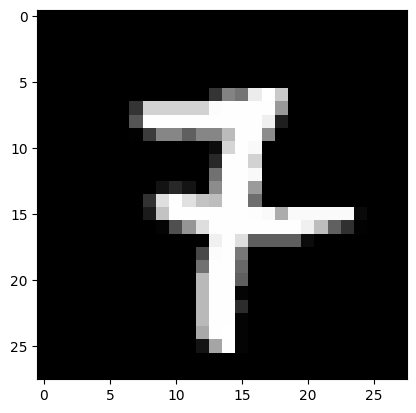

In [215]:
test_prediction(106, W1, b1, W2, b2)